# <center>MTH 468 Project 2</center>

# Part 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Given function
def f(x):
    return x**2 + x -6

# f'(x)
def f_d(x):
    return 2*x +1

# f''(x)
def f_dd(x):
    return 2

Critical points (Extrema): [-0.5]


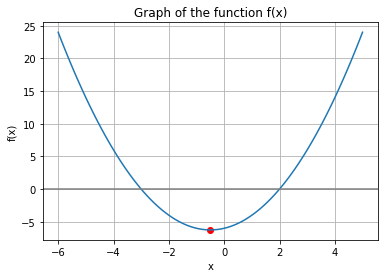

In [2]:
# a: Graph of the function f(x)
x_values = np.linspace(-6, 5, 100)
plt.plot(x_values, f(x_values), label='f(x) = x^2 + x - 6')
plt.axhline(0, color = 'grey')
critical_points = np.roots([2, 1])
plt.scatter(critical_points, f(critical_points), color ='r')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Graph of the function f(x)')
plt.grid(True)
print("Critical points (Extrema):", critical_points)

In [3]:
# b: Using Newton's method to find roots
def nmr(x0, max_iter=100, tol=1e-6):
    x = x0
    x_new = x - f(x)/f_d(x)
    cnt = 1
    
    while ((abs(x_new - x) > tol) and (cnt < max_iter)):
        x = x_new
        x_new = x - f(x)/f_d(x)
        cnt +=1
        print("Root: ", x_new, "\nFunction Value: ", f(x_new), "\nIteration Count: ", cnt, "\n")
        
    return x, cnt

print("Roots using Newton's method:")
roots = [-10, 2]
for root in roots:
    root_value, iterations = nmr(root)
    print(f"Root at x = {root_value}, iterations = {iterations}")


Roots using Newton's method:
Root:  -3.6547586583037903 
Function Value:  3.702502192142731 
Iteration Count:  2 

Root:  -3.067946386246592 
Function Value:  0.3443486426369313 
Iteration Count:  3 

Root:  -3.00089891117445 
Function Value:  0.004495363913549433 
Iteration Count:  4 

Root:  -3.0000001615501724 
Function Value:  8.077508883985729e-07 
Iteration Count:  5 

Root:  -3.0000000000000053 
Function Value:  2.6645352591003757e-14 
Iteration Count:  6 

Root at x = -3.0000001615501724, iterations = 6
Root at x = 2, iterations = 1


In [4]:
# c: Using gradient descent to locate minimum value

import pandas as pd

def GD(x0, alpha, tol, max_iter):

    def f(x):
        return x**2 + x -6

    # f'(x)
    def f_d(x):
        return 2*x +1

    # f''(x)
    def f_dd(x):
        return 2

    x_new = x0 - (alpha * f_d(x0))
    count = 1
    
    iteration = []
    x_value = []
    y_value = []
    f_d_value = []
    
    iteration.append(count)
    x_value.append(x0)
    y_value.append(f(x0))
    f_d_value.append(f_d(x0))
    
    while (abs(x_new - x0) > tol) and (count < max_iter):
        x0 = x_new
        x_new = x0 - (alpha * f_d(x0))
        count += 1
        
        iteration.append(count)
        x_value.append(x0)
        y_value.append(f(x0))
        f_d_value.append(f_d(x0))
        
    iteration.append(count + 1)
    x_value.append(x_new)
    y_value.append(f_d(x_new))
    f_d_value.append(f_d(x_new))

    global info_f_d_GD                  
    I = np.array(iteration)
    X = np.array(x_value)
    Y = np.array(y_value)
    f_d = np.array(f_d_value)
    
    info_f_d_GD = pd.DataFrame(np.vstack((I, X, Y, f_d))).T
    
    info_f_d_GD = info_f_d_GD.rename(columns = {0:"Iteration Count", 
                                              1: "x",
                                              2: "f(x)", 
                                              3: "f_d(x)"})       
    
    info_f_d_GD = info_f_d_GD.round({"Iteration Count":0,
                                   "x": 2, 
                                   "f(x)":4, 
                                   "f_d(x)":4})
    
    info_f_d_GD = info_f_d_GD.astype({"Iteration Count": int})
    
    # Colors
    colors_f_d = []
    global colors, color_cat 
    colors = np.array(["r", "y", "g", "b", "c", "m"])               
    color_cat = info_f_d_GD.index % 6   
    
    for i in info_f_d_GD.index:
        colors_f_d.append(colors[i % 6])

    info_f_d_GD["Color"] = colors_f_d

    print("Minimum  ", x_new, "\nIteration Count: ", count)
    return x_new

Minimum   262680684693881945552099464485716620386653788022183382294165058769355183138023197654974705170119251611598558295560512404741323003 
Iteration Count:  100
   Iteration Count       x          f(x)  f_d(x) Color
0                1       3             6       7     r
1                2     -67          4416    -133     y
2                3    1263       1596426    2527     g
3                4  -24007     576312036  -48013     b
4                5  456123  208048647246  912247     c


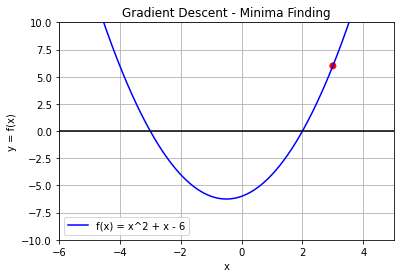

<Figure size 432x288 with 0 Axes>

In [5]:
# GD(x0, alpha, tol, max_iter):
GD(3, 10, 0.0001, 100)   
print(info_f_d_GD.head())


x_space = np.linspace(-6,5,1000)   
plt.title("Gradient Descent - Minima Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")                           
plt.scatter(info_f_d_GD.x, f(info_f_d_GD.x), c = colors[color_cat]) 
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-6,5)); plt.ylim((-10,10))
plt.legend()    
plt.grid()
plt.show()                                                       
plt.clf() 


Minimum   3 
Iteration Count:  1000
      Iteration Count  x  f(x)  f_d(x) Color
0                   1  3     6       7     r
1                   2 -4     6      -7     y
2                   3  3     6       7     g
3                   4 -4     6      -7     b
4                   5  3     6       7     c
...               ... ..   ...     ...   ...
996               997  3     6       7     r
997               998 -4     6      -7     y
998               999  3     6       7     g
999              1000 -4     6      -7     b
1000             1001  3     7       7     c

[1001 rows x 5 columns]


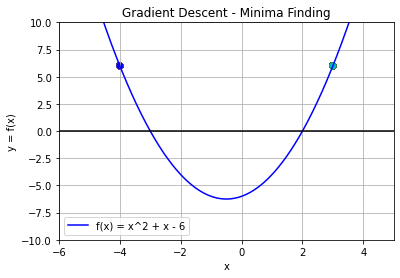

<Figure size 432x288 with 0 Axes>

In [6]:
GD(3, 1, 0.0001, 1000)
print(info_f_d_GD)

x_space = np.linspace(-6,5,1000)   
plt.title("Gradient Descent - Minima Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")                           
plt.scatter(info_f_d_GD.x, f(info_f_d_GD.x), c = colors[color_cat]) 
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-6,5)); plt.ylim((-10,10))
plt.legend()    
plt.grid()
plt.show()                                                       
plt.clf() 


Minimum   -0.49962781616118024 
Iteration Count:  41
    Iteration Count     x    f(x)  f_d(x) Color
0                 1  3.00  6.0000  7.0000     r
1                 2  2.30  1.5900  5.6000     y
2                 3  1.74 -1.2324  4.4800     g
3                 4  1.29 -3.0387  3.5840     b
4                 5  0.93 -4.1948  2.8672     c
5                 6  0.65 -4.9347  2.2938     m
6                 7  0.42 -5.4082  1.8350     r
7                 8  0.23 -5.7112  1.4680     y
8                 9  0.09 -5.9052  1.1744     g
9                10 -0.03 -6.0293  0.9395     b
10               11 -0.12 -6.1088  0.7516     c
11               12 -0.20 -6.1596  0.6013     m
12               13 -0.26 -6.1922  0.4810     r
13               14 -0.31 -6.2130  0.3848     y
14               15 -0.35 -6.2263  0.3079     g
15               16 -0.38 -6.2348  0.2463     b
16               17 -0.40 -6.2403  0.1970     c
17               18 -0.42 -6.2438  0.1576     m
18               19 -0.44 -6.2460  

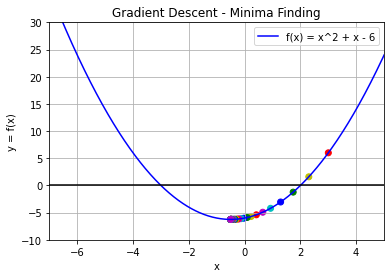

<Figure size 432x288 with 0 Axes>

In [7]:
GD(3, 0.1, 0.0001, 1000)
print(info_f_d_GD)


x_space = np.linspace(-10,5,1000)
plt.title("Gradient Descent - Minima Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_f_d_GD.x, f(info_f_d_GD.x), c = colors[color_cat]) 
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-7,5)); plt.ylim((-10,30))
plt.legend()
plt.grid()
plt.show()
plt.clf()



Minimum   -0.4951719837840201 
Iteration Count:  326
     Iteration Count     x    f(x)  f_d(x) Color
0                  1  3.00  6.0000  7.0000     r
1                  2  2.93  5.5149  6.8600     y
2                  3  2.86  5.0490  6.7228     g
3                  4  2.79  4.6016  6.5883     b
4                  5  2.73  4.1718  6.4566     c
..               ...   ...     ...     ...   ...
322              323 -0.49 -6.2500  0.0105     c
323              324 -0.49 -6.2500  0.0103     m
324              325 -0.49 -6.2500  0.0101     r
325              326 -0.50 -6.2500  0.0099     y
326              327 -0.50  0.0097  0.0097     g

[327 rows x 5 columns]


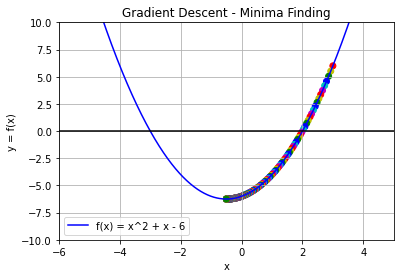

<Figure size 432x288 with 0 Axes>

In [8]:
GD(3, 0.01, 0.0001, 1000)
print(info_f_d_GD)

x_space = np.linspace(-6,5,1000)
plt.title("Gradient Descent - Minima Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_f_d_GD.x, f(info_f_d_GD.x), c = colors[color_cat]) 
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-6,5)); plt.ylim((-10,10))
plt.legend()
plt.grid()
plt.show()
plt.clf()


Minimum   -0.450187568820033 
Iteration Count:  2124
      Iteration Count     x    f(x)  f_d(x) Color
0                   1  3.00  6.0000  7.0000     r
1                   2  2.99  5.9510  6.9860     y
2                   3  2.99  5.9023  6.9720     g
3                   4  2.98  5.8537  6.9581     b
4                   5  2.97  5.8054  6.9442     c
...               ...   ...     ...     ...   ...
2120             2121 -0.45 -6.2475  0.1004     g
2121             2122 -0.45 -6.2475  0.1002     b
2122             2123 -0.45 -6.2475  0.1000     c
2123             2124 -0.45 -6.2475  0.0998     m
2124             2125 -0.45  0.0996  0.0996     r

[2125 rows x 5 columns]


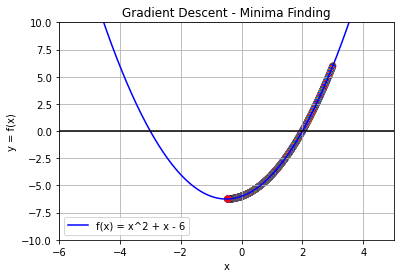

<Figure size 432x288 with 0 Axes>

In [9]:
GD(3, 0.001, 0.0001, 10000)

print(info_f_d_GD)

x_space = np.linspace(-6,5,1000)
plt.title("Gradient Descent - Minima Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0.0, "k")
plt.scatter(info_f_d_GD.x, f(info_f_d_GD.x), c = colors[color_cat]) 
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-6,5)); plt.ylim((-10,10))
plt.legend()    
plt.grid()
plt.show()                                                       
plt.clf() 


- Larger learning rates (e.g.,α=10) causes the algorithm to overshoot and oscillate around the minimum or even diverge.
- Smaller learning rates (e.g., α=0.001) leads to slow convergence but more stable behavior.
- The learning rate α=1.0 is a critical point, as it can either lead to convergence or divergence depending on the specific function and initial point.
- By observing the plotted convergence curves, we can evaluate the effectiveness of each learning rate in minimizing the function f(x) and make adjustments as needed for better convergence.

Extrema at x =  -0.5 
Derivative Value:  0.0 
Iteration Count:  1 

   Iteration Count    x  f_d(x) Color
0                1  5.0    11.0     r
1                2 -0.5     0.0     y


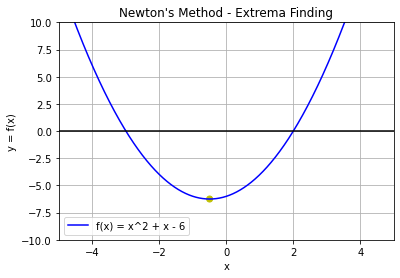

<Figure size 432x288 with 0 Axes>

In [10]:
# d: Using Newton's Method to locate minimum value

def nm_opt(x0, tol, max_iter):         
    x_new = x0 - f_d(x0)/f_dd(x0)
    count = 1
    
    iteration = []
    x_value = []
    y_value = []
    
    iteration.append(count)
    x_value.append(x0)
    y_value.append(f_d(x0))
    
    while ((abs(f_d(x_new)) > tol) and (count < max_iter)):      
        x0 = x_new                         
        x_new = x0 - f_d(x0)/f_dd(x0)
        count +=1
        
        iteration.append(count)
        x_value.append(x0)
        y_value.append(f_d(x0))
        
    iteration.append(count + 1)
    x_value.append(x_new)
    y_value.append(f_d(x_new))
    
    global info_DF_opt                  
    I = np.array(iteration)
    X = np.array(x_value)
    Y = np.array(y_value)
    
    info_DF_opt = pd.DataFrame(np.vstack((I, X, Y))).T
    
    # Columns
    info_DF_opt = info_DF_opt.rename(columns = {0:"Iteration Count",
                                               1: "x",
                                               2: "f_d(x)"})      
    
    info_DF_opt = info_DF_opt.round({"Iteration Count":0,
                                     "x": 2,
                                     "f_d(x)":4})
    
    info_DF_opt = info_DF_opt.astype({"Iteration Count": int})
    
    # Colors
    global colors, color_cat
    colors_DF = []
    colors = np.array(["r", "y", "g", "b", "c", "m"])                 
    color_cat = info_DF_opt.index % 6   
    
    for i in info_DF_opt.index:
        colors_DF.append(colors[i % 6])

    info_DF_opt["Color"] = colors_DF
    
    print("Extrema at x = ", x_new, "\nDerivative Value: ", f_d(x_new), "\nIteration Count: ", count, "\n")
    return x0

nm_opt(5, 0.0001, 1000)

print(info_DF_opt)

x_space = np.linspace(-5,5,1000)   
plt.title("Newton's Method - Extrema Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_DF_opt.x, f(info_DF_opt.x), c = colors[color_cat])
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-5,5)); plt.ylim((-10,10))
plt.grid()
plt.legend()
plt.show()
plt.clf()

Extrema at x =  -0.5 
Derivative Value:  0.0 
Iteration Count:  1 

   Iteration Count    x  f_d(x) Color
0                1  2.0     5.0     r
1                2 -0.5     0.0     y


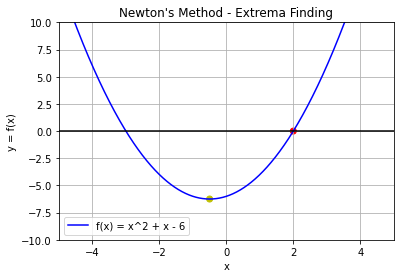

<Figure size 432x288 with 0 Axes>

In [11]:
nm_opt(2, 0.0001, 1000)

print(info_DF_opt)

x_space = np.linspace(-5,5,1000)   
plt.title("Newton's Method - Extrema Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_DF_opt.x, f(info_DF_opt.x), c = colors[color_cat])
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-5,5)); plt.ylim((-10,10))
plt.grid()
plt.legend()
plt.show()
plt.clf()

Extrema at x =  -0.5 
Derivative Value:  0.0 
Iteration Count:  1 

   Iteration Count    x  f_d(x) Color
0                1 -5.0    -9.0     r
1                2 -0.5     0.0     y


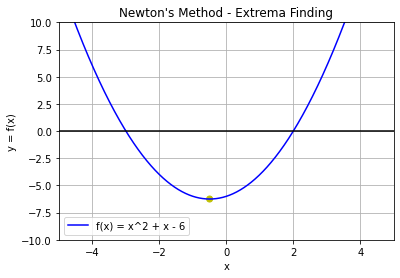

<Figure size 432x288 with 0 Axes>

In [12]:
nm_opt(-5, 0.0001, 1000)

print(info_DF_opt)

x_space = np.linspace(-5,5,1000)   
plt.title("Newton's Method - Extrema Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_DF_opt.x, f(info_DF_opt.x), c = colors[color_cat])
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-5,5)); plt.ylim((-10,10))
plt.grid()
plt.legend()
plt.show()
plt.clf()

Extrema at x =  -0.5 
Derivative Value:  0.0 
Iteration Count:  1 

   Iteration Count    x  f_d(x) Color
0                1 -2.0    -3.0     r
1                2 -0.5     0.0     y


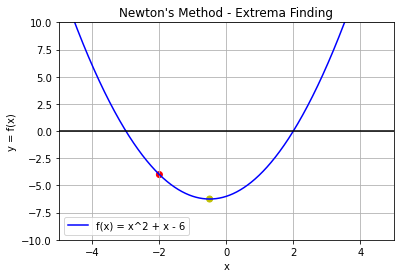

<Figure size 432x288 with 0 Axes>

In [13]:
nm_opt(-2, 0.0001, 1000)

print(info_DF_opt)

x_space = np.linspace(-5,5,1000)   
plt.title("Newton's Method - Extrema Finding")
plt.plot(x_space, f(x_space), color = "blue", label = "f(x) = x^2 + x - 6")
plt.plot(x_space, x_space*0, "k")
plt.scatter(info_DF_opt.x, f(info_DF_opt.x), c = colors[color_cat])
plt.xlabel("x"); plt.ylabel("y = f(x)")
plt.xlim((-5,5)); plt.ylim((-10,10))
plt.grid()
plt.legend()
plt.show()
plt.clf()

# Part 2

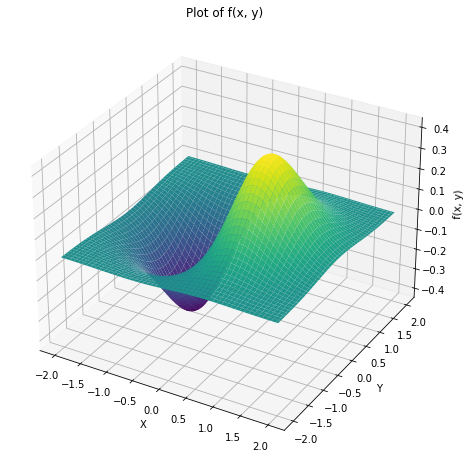

In [14]:
# a: Graph of f(x, y)

from mpl_toolkits.mplot3d import Axes3D

# Define function
def f(x, y):
    return x * np.exp(-(x**2 + y**2))

# Generate data
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)

# Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('f(x, y)')
ax.set_title('Plot of f(x, y)')
plt.show()


In [15]:
# b: Locate Extrema using GD, GA

# Define function
def f(x, y):
    return x * np.exp(-(x**2 + y**2))

# Define partial derivs
def df_dx(x, y):
    return np.exp(-(x**2 + y**2)) - 2 * x**2 * np.exp(-(x**2 + y**2))

def df_dy(x, y):
    return -2 * x * y * np.exp(-(x**2 + y**2))

# Gradient Descent
def GD(x0, y0, alpha, tol, max_iter):
    x_new, y_new = x0, y0
    count = 1
    
    iteration = []
    x_value = []
    y_value = []
    dfx_value = []
    dfy_value = []
    
    iteration.append(count)
    x_value.append(x0)
    y_value.append(y0)
    dfx_value.append(df_dx(x0, y0))
    dfy_value.append(df_dy(x0, y0))
    
    while (count < max_iter):
        x0, y0 = x_new, y_new
        x_new = x0 - (alpha * df_dx(x0, y0))
        y_new = y0 - (alpha * df_dy(x0, y0))
        count += 1
        
        iteration.append(count)
        x_value.append(x_new)
        y_value.append(y_new)
        dfx_value.append(df_dx(x_new, y_new))
        dfy_value.append(df_dy(x_new, y_new))
        
    global info_DF_GD
    info_DF_GD = pd.DataFrame({
        "Iteration Count": iteration,
        "x": x_value,
        "y": y_value,
        "df_dx": dfx_value,
        "df_dy": dfy_value
    })
    
    print("Minimum at (x, y): ", x_new, y_new, "\nIteration Count: ", count)
    
    return x_new, y_new

# Gradient Ascent
def GA(x0, y0, alpha, tol, max_iter):
    x_new, y_new = x0, y0
    count = 1
    
    iteration = []
    x_value = []
    y_value = []
    dfx_value = []
    dfy_value = []
    
    iteration.append(count)
    x_value.append(x0)
    y_value.append(y0)
    dfx_value.append(df_dx(x0, y0))
    dfy_value.append(df_dy(x0, y0))
    
    while (count < max_iter):
        x0, y0 = x_new, y_new
        x_new = x0 + (alpha * df_dx(x0, y0))
        y_new = y0 + (alpha * df_dy(x0, y0))
        count += 1
        
        iteration.append(count)
        x_value.append(x_new)
        y_value.append(y_new)
        dfx_value.append(df_dx(x_new, y_new))
        dfy_value.append(df_dy(x_new, y_new))
        
    global info_DF_GA
    info_DF_GA = pd.DataFrame({
        "Iteration Count": iteration,
        "x": x_value,
        "y": y_value,
        "df_dx": dfx_value,
        "df_dy": dfy_value
    })
    
    print("Maximum at (x, y): ", x_new, y_new, "\nIteration Count: ", count)
    
    return x_new, y_new

# Initial values
x0, y0 = 0.5, 0.5
alpha_values = [10, 1.0, 0.1, 0.01, 0.001]
tol = 0.0001
max_iter = 1000

print('GD:')
# Apply GD
for alpha in alpha_values:
    GD(x0, y0, alpha, tol, max_iter)

print('\nGA:')
# Apply GA
for alpha in alpha_values:
    GA(x0, y0, alpha, tol, max_iter)


GD:
Minimum at (x, y):  -2.5319138540047756 3.531534680110878 
Iteration Count:  1000
Minimum at (x, y):  -0.7071067811865475 0.0 
Iteration Count:  1000
Minimum at (x, y):  -0.7071067811865472 5.456892822624529e-39 
Iteration Count:  1000
Minimum at (x, y):  -0.7071065118846415 0.0006405048114934868 
Iteration Count:  1000
Minimum at (x, y):  0.017605934922683 0.7071471385933302 
Iteration Count:  1000

GA:
Maximum at (x, y):  3.5311522593283957 -2.5315322384282672 
Iteration Count:  1000
Maximum at (x, y):  0.7071067811865476 0.0 
Iteration Count:  1000
Maximum at (x, y):  0.7071067811865472 7.393471038165024e-40 
Iteration Count:  1000
Maximum at (x, y):  0.7071067736149039 0.00010741961851902857 
Iteration Count:  1000
Maximum at (x, y):  0.6647480960784621 0.2411488250293137 
Iteration Count:  1000


In [16]:
# c: Locate Extrema with Newtons Method

# Define Hessian matrix
def hessian(x, y):
    d2f_dx2 = (4 * x**3 - 6*x) * np.exp(-x**2 - y**2)
    d2f_dy2 = (4 * y**3 - 6*y) * np.exp(-x**2 - y**2)
    d2f_dxdy = 4*x*y * (1 - 2*x**2) * np.exp(-x**2 - y**2)
    
    hess = np.array([[d2f_dx2, d2f_dxdy], [d2f_dxdy, d2f_dy2]])
    regularization = 1e-6 * np.eye(2)  # Add small value to diagonal elements
    return hess + regularization

# Newton's Method for optimization
def nm_opt(x0, y0, tol, max_iter):         
    x = np.array([x0, y0], dtype=float)
    iteration = []
    x_value = []
    y_value = []
    
    iteration.append(0)
    x_value.append(x0)
    y_value.append(y0)
    
    for count in range(1, max_iter + 1):
        deriv = np.array([df_dx(x[0], x[1]), df_dy(x[0], x[1])])
        hess_inv = np.linalg.pinv(hessian(x[0], x[1]))
        delta = np.dot(hess_inv, deriv)
        
        x -= delta
        iteration.append(count)
        x_value.append(x[0])
        y_value.append(x[1])
        
        if np.linalg.norm(delta) < tol:
            break
    
    global info_NM_opt                  
    info_NM_opt = pd.DataFrame({
        "Iteration Count": iteration,
        "x": x_value,
        "y": y_value
    })
    
    print("Extrema at (x, y) =", (x[0], x[1]), "\nDerivative Value:", deriv, "\nIteration Count:", count, "\n")
    
    return x[0], x[1]

nm_opt(0.5, 0, 0.0001, 1000)
nm_opt(2, 0, 0.0001, 1000)
nm_opt(-2, 0, 0.0001, 1000)


Extrema at (x, y) = (0.7071067803583683, 0.0) 
Derivative Value: [ 5.94279094e-05 -0.00000000e+00] 
Iteration Count: 3 

Extrema at (x, y) = (5.191775273538395, 0.0) 
Derivative Value: [-1.04178419e-10 -0.00000000e+00] 
Iteration Count: 1000 

Extrema at (x, y) = (-6.576311715266542, 0.0) 
Derivative Value: [-1.41133701e-17  0.00000000e+00] 
Iteration Count: 94 



(-6.576311715266542, 0.0)

d: Commenting on importance of starting position 
- If the initial starting position is close to the extrema, Newton's method tends to converge quickly to the extrema with fewer iterations.
- However, if the initial starting position is far from the extrema or falls into a region where the function behaves unpredictably (e.g., near points of inflection), Newton's method may diverge or converge to a local extremum instead of the global one.
- In the case where the function has multiple extrema or critical points, the choice of the initial starting position can affect which extremum the method converges to. Different initial starting positions may lead to converging to different extrema.

# Part 3

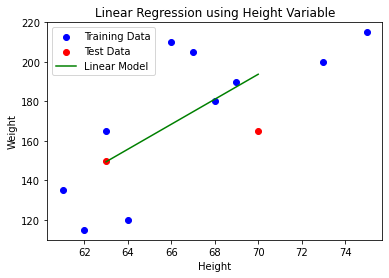

In [17]:
# a: Use Linear Regression for Height and Show Plot

from sklearn.linear_model import LinearRegression
data = pd.read_excel("Weight.xlsx")

# Split data into training and testing
train_data = data.iloc[:10]
test_data = data.iloc[10:]

# Do linear regression using height
X_train = train_data[['Height']]
y_train = train_data['Weight']
X_test = test_data[['Height']]
y_test = test_data['Weight']
model_height = LinearRegression()
model_height.fit(X_train, y_train)

# Predict test data
y_pred_height = model_height.predict(X_test)

# Plot data and linear regression
plt.scatter(train_data['Height'], train_data['Weight'], color='blue', label='Training Data')
plt.scatter(test_data['Height'], test_data['Weight'], color='red', label='Test Data')
plt.plot(X_test, y_pred_height, color='green', label='Linear Model')
plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Linear Regression using Height Variable')
plt.legend()
plt.show()

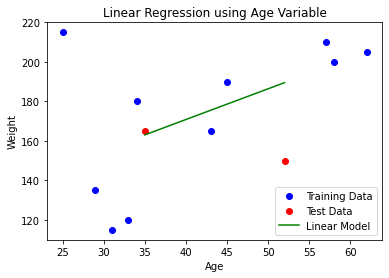

In [18]:
# b: Use Linear Regression for Age and Show Plot

# Do linear regression using age
X_train_age = train_data[['Age']]
X_test_age = test_data[['Age']]
model_age = LinearRegression()
model_age.fit(X_train_age, y_train)

# Predict test data
y_pred_age = model_age.predict(X_test_age)

# Plot data and linear regression
plt.scatter(train_data['Age'], train_data['Weight'], color='blue', label='Training Data')
plt.scatter(test_data['Age'], test_data['Weight'], color='red', label='Test Data')
plt.plot(X_test_age, y_pred_age, color='green', label='Linear Model')
plt.xlabel('Age')
plt.ylabel('Weight')
plt.title('Linear Regression using Age Variable')
plt.legend()
plt.show()

In [19]:
# c: Use Multiple Linear Regression for Age, Height, and Age*Height

# Adding age*height column
data["Age*Height"] = data["Age"] * data["Height"]

# Extract training data
X_train = data[["Age", "Height", "Age*Height"]][:10]

# Create multiple linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Coefficients:", model.coef_)

# Predict weights
X_test = data[["Age", "Height", "Age*Height"]][10:]
y_pred = model.predict(X_test)
print(X_test)
print(y_pred)

Coefficients: [18.68092951 14.48685314 -0.25465495]
    Age  Height  Age*Height
10   52      63        3276
11   35      70        2450
[188.47636383 182.65352149]


- Coefficient for Age (18.68092951): This coefficient represents the change in weight for a one-unit increase in age, holding height and the age*height term constant.

- Coefficient for Height (14.48685314): This coefficient represents the change in weight for a one-unit increase in height, holding age and the age*height term constant.

- Coefficient for Age*Height (-0.25465495): This coefficient represents the interaction effect between age and height on weight. It indicates how the change in weight due to age varies with height. Since this coefficient is negative, it suggests that the effect of age on weight decreases as height increases.